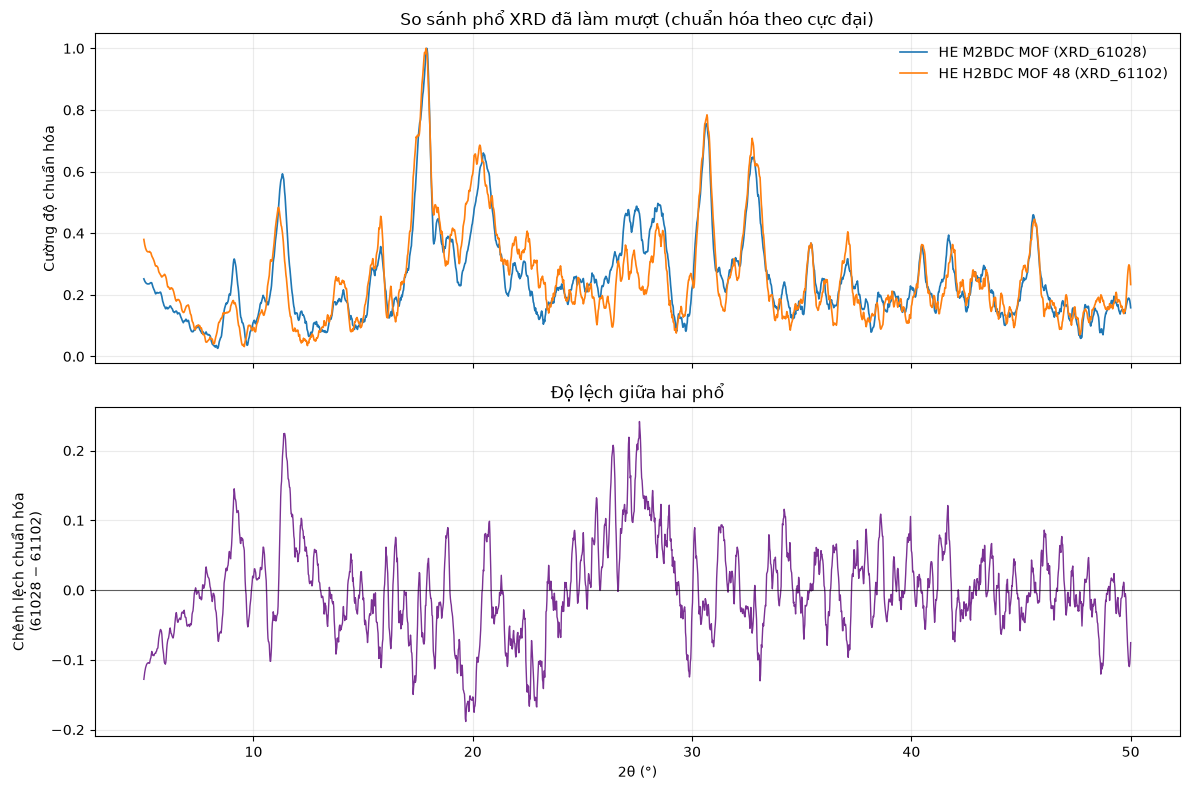

Khoảng 2θ chung: 5.00°–50.00° (2,251 điểm)
Tương quan Pearson giữa hai phổ chuẩn hóa: 0.9042
RMSE của cường độ chuẩn hóa: 0.0668
Khoảng 2θ chung: 5.00°–50.00° (2,251 điểm)
Tương quan Pearson (r): 0.9042
Độ tương đồng Cosine:  0.9686
RMSE chuẩn hóa:        0.0690


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
search_roots = [_here, *_here.parents]
project_root = next(
    (
        candidate
        for root in search_roots
        for candidate in (root, root / "projects")
        if all((candidate / sample_id / "processed").is_dir() for sample_id in ("XRD_61028", "XRD_61102"))
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy thư mục dự án chứa cả XRD_61028 và XRD_61102")

comparison_files = {
    "HE M2BDC MOF (XRD_61028)": project_root / "XRD_61028" / "processed" / "HE_M2BDC_MOF_smoothed.xy",
    "HE H2BDC MOF 48 (XRD_61102)": project_root / "XRD_61102" / "processed" / "HE_H2BDC_MOF_48_smoothed.xy",
}
comparison_data = {}
for sample_name, file_path in comparison_files.items():
    if not file_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy output cell 6 cho {sample_name}: {file_path}")
    sample_data = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        names=["two_theta", "intensity"],
    )
    sample_data = sample_data.apply(pd.to_numeric, errors="coerce").dropna()
    sample_data = sample_data.sort_values("two_theta").reset_index(drop=True)
    if sample_data.empty or sample_data["two_theta"].duplicated().any():
        raise ValueError(f"Dữ liệu 2θ không hợp lệ trong {file_path}")
    comparison_data[sample_name] = sample_data

first_name, second_name = comparison_data
first_data = comparison_data[first_name]
second_data = comparison_data[second_name]
common_min = max(first_data["two_theta"].min(), second_data["two_theta"].min())
common_max = min(first_data["two_theta"].max(), second_data["two_theta"].max())
first_common = first_data.loc[first_data["two_theta"].between(common_min, common_max)]
comparison_theta = first_common["two_theta"].to_numpy(dtype=float)
if len(comparison_theta) == 0:
    raise ValueError("Hai phổ không có khoảng 2θ chung để so sánh")

first_intensity = first_common["intensity"].to_numpy(dtype=float)
second_intensity = np.interp(
    comparison_theta,
    second_data["two_theta"].to_numpy(dtype=float),
    second_data["intensity"].to_numpy(dtype=float),
)
first_scale = first_intensity.max()
second_scale = second_intensity.max()
if first_scale <= 0 or second_scale <= 0:
    raise ValueError("Không thể chuẩn hóa phổ vì cường độ cực đại phải lớn hơn 0")
first_normalized = first_intensity / first_scale
second_normalized = second_intensity / second_scale
intensity_difference = first_normalized - second_normalized

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(comparison_theta, first_normalized, label=first_name, linewidth=1.2)
axes[0].plot(comparison_theta, second_normalized, label=second_name, linewidth=1.2)
axes[0].set_ylabel("Cường độ chuẩn hóa")
axes[0].set_title("So sánh phổ XRD đã làm mượt (chuẩn hóa theo cực đại)")
axes[0].legend(frameon=False)
axes[0].grid(True, alpha=0.25)

axes[1].plot(comparison_theta, intensity_difference, color="#7b3294", linewidth=1.0)
axes[1].axhline(0, color="black", linewidth=0.8, alpha=0.6)
axes[1].set_xlabel("2θ (°)")
axes[1].set_ylabel("Chênh lệch chuẩn hóa\n(61028 − 61102)")
axes[1].set_title("Độ lệch giữa hai phổ")
axes[1].grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

correlation = np.corrcoef(first_normalized, second_normalized)[0, 1]
rmse = np.sqrt(np.mean(intensity_difference ** 2))
print(f"Khoảng 2θ chung: {common_min:.2f}°–{common_max:.2f}° ({len(comparison_theta):,} điểm)")
print(f"Tương quan Pearson giữa hai phổ chuẩn hóa: {correlation:.4f}")
print(f"RMSE của cường độ chuẩn hóa: {rmse:.4f}")

# 1. Nội suy cả hai phổ về lưới 2theta đều đặn (bước 0.02°)
step = 0.02
comparison_theta = np.arange(common_min, common_max + step / 2, step)
first_intensity = np.interp(comparison_theta, first_data["two_theta"].to_numpy(float), first_data["intensity"].to_numpy(float))
second_intensity = np.interp(comparison_theta, second_data["two_theta"].to_numpy(float), second_data["intensity"].to_numpy(float))

# 2. Chuẩn hóa Min-Max (đưa đáy về 0 và đỉnh về 1) để giảm bớt ảnh hưởng của nền cao
first_normalized = (first_intensity - first_intensity.min()) / (first_intensity.max() - first_intensity.min())
second_normalized = (second_intensity - second_intensity.min()) / (second_intensity.max() - second_intensity.min())
intensity_difference = first_normalized - second_normalized

# 3. Tính các chỉ số đánh giá
correlation = np.corrcoef(first_normalized, second_normalized)[0, 1]
cosine_sim = np.dot(first_normalized, second_normalized) / (np.linalg.norm(first_normalized) * np.linalg.norm(second_normalized))
rmse = np.sqrt(np.mean(intensity_difference ** 2))

print(f"Khoảng 2θ chung: {common_min:.2f}°–{common_max:.2f}° ({len(comparison_theta):,} điểm)")
print(f"Tương quan Pearson (r): {correlation:.4f}")
print(f"Độ tương đồng Cosine:  {cosine_sim:.4f}")
print(f"RMSE chuẩn hóa:        {rmse:.4f}")

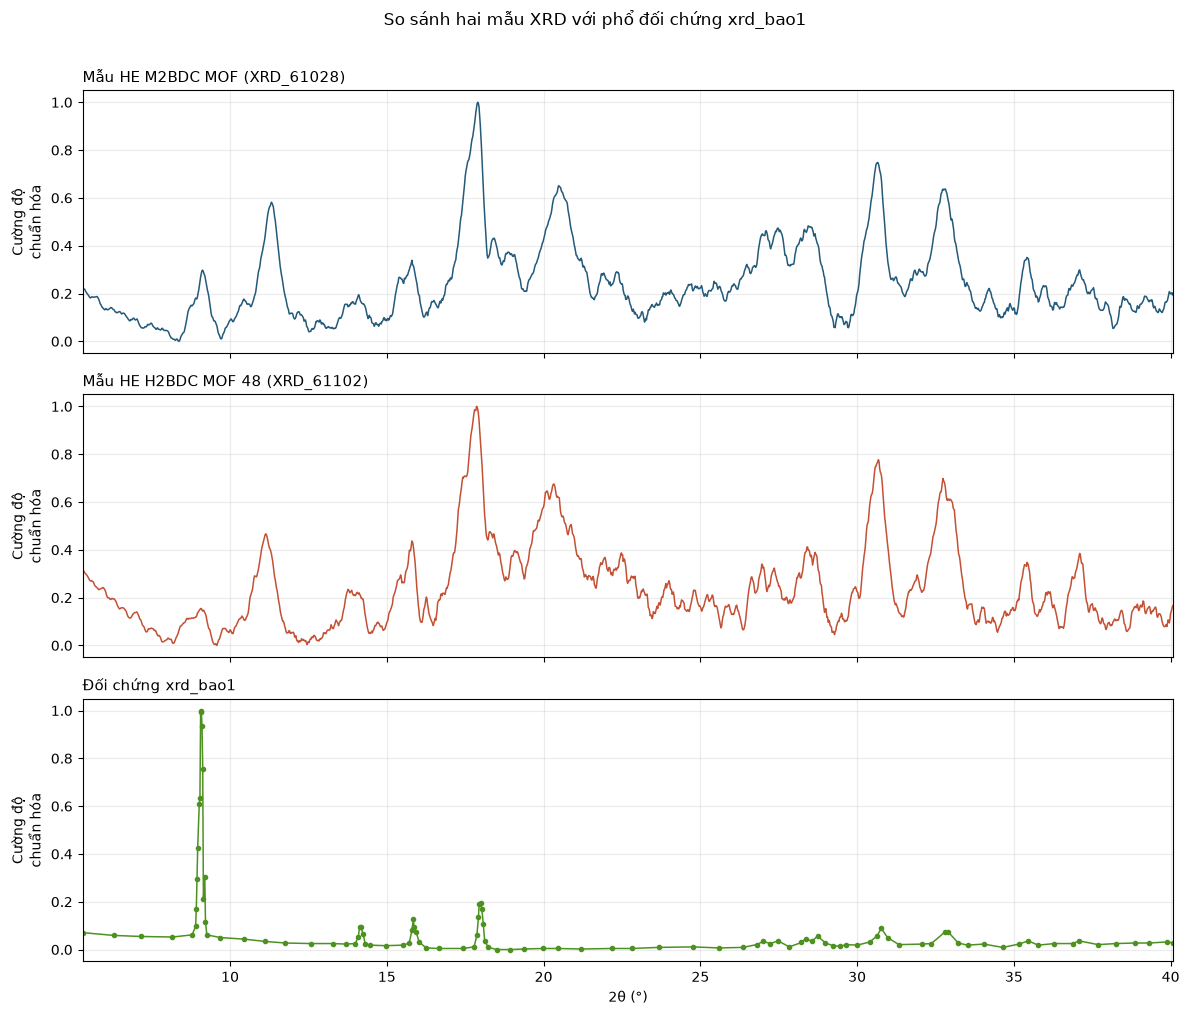

Khoảng 2θ chung của ba phổ: 5.29°–40.08°


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
project_roots = [_here, *_here.parents]
project_root = next(
    (
        candidate
        for root in project_roots
        for candidate in (root, root / "projects")
        if all((candidate / sample_id / "processed").is_dir() for sample_id in ("XRD_61028", "XRD_61102"))
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy thư mục chứa cả XRD_61028 và XRD_61102")

spectrum_files = [
    (
        "Mẫu HE M2BDC MOF (XRD_61028)",
        project_root / "XRD_61028" / "processed" / "HE_M2BDC_MOF_smoothed.xy",
    ),
    (
        "Mẫu HE H2BDC MOF 48 (XRD_61102)",
        project_root / "XRD_61102" / "processed" / "HE_H2BDC_MOF_48_smoothed.xy",
    ),
    ("Đối chứng xrd_bao1", project_root / "XRD_61028" / "raw" / "xrd_bao1.txt"),
]

spectra = []
for label, file_path in spectrum_files:
    if not file_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy phổ {label}: {file_path}")
    spectrum = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        names=["two_theta", "intensity"],
    )
    spectrum = spectrum.apply(pd.to_numeric, errors="coerce").dropna()
    spectrum = spectrum[np.isfinite(spectrum["two_theta"]) & np.isfinite(spectrum["intensity"])]
    spectrum = (
        spectrum.groupby("two_theta", as_index=False)["intensity"]
        .mean()
        .sort_values("two_theta")
        .reset_index(drop=True)
    )
    if len(spectrum) < 2:
        raise ValueError(f"Phổ không đủ điểm hợp lệ để vẽ: {file_path}")
    spectra.append((label, spectrum))

common_min = max(spectrum["two_theta"].min() for _, spectrum in spectra)
common_max = min(spectrum["two_theta"].max() for _, spectrum in spectra)
if common_min >= common_max:
    raise ValueError("Ba phổ không có khoảng 2θ chung để so sánh")

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
colors = ["#245a7a", "#c45135", "#4d9221"]
for ax, (label, spectrum), color in zip(axes, spectra, colors):
    visible = spectrum.loc[spectrum["two_theta"].between(common_min, common_max)]
    intensity = visible["intensity"].to_numpy(dtype=float)
    intensity_range = np.ptp(intensity)
    if len(visible) < 2 or intensity_range <= 0:
        raise ValueError(f"Phổ không có biến thiên cường độ trong khoảng chung: {label}")
    normalized = (intensity - intensity.min()) / intensity_range
    if "xrd_bao1" in label:
        ax.plot(visible["two_theta"], normalized, color=color, linewidth=1.1, marker="o", markersize=3)
    else:
        ax.plot(visible["two_theta"], normalized, color=color, linewidth=1.1)
    ax.set_title(label, loc="left", fontsize=11)
    ax.set_ylabel("Cường độ\nchuẩn hóa")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.25)

axes[-1].set_xlabel("2θ (°)")
axes[-1].set_xlim(common_min, common_max)
fig.suptitle("So sánh hai mẫu XRD với phổ đối chứng xrd_bao1", y=1.01)
fig.tight_layout()
plt.show()
print(f"Khoảng 2θ chung của ba phổ: {common_min:.2f}°–{common_max:.2f}°")